# 06 — Supervised Classification & McNemar Significance Testing
**Analytics and Systems of Big Data Practice — Endsem Hackathon**
*IIITDM Kancheepuram*

## 1. Classification Setup & The Honest 55.46% Baseline
Evaluate Gaussian Naive Bayes (continuous) and Bernoulli Naive Bayes (binary) against the test majority baseline.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path(os.getcwd()).resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from src.config import *
from IPython.display import Image, display

from src.classification import execute_classification_pipeline
df_clf = pd.read_csv(TABLES_DIR / 'table_14_classification_metrics_S&P.csv')
df_clf

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Balanced_Accuracy,MCC,Binomial_p_vs_Majority,TP,FP,TN,FN,McNemar_Stat_vs_Base,McNemar_pVal_vs_Base,Index,Train_Majority_Class,Train_Majority_Ratio,Test_Majority_Ratio,Baseline_Test_Accuracy
0,Majority_Baseline,0.5546,0.5546,1.0000,0.7135,0.5000,0.5000,0.0000,0.5220,198,159,0,0,0.0000,1.0000,S&P,1,0.5432,0.5546,0.5546
1,GaussianNB_Continuous,0.5014,0.5340,0.7929,0.6382,0.5176,0.4656,-0.0896,0.9809,157,137,22,41,5.1429,0.0233,S&P,1,0.5432,0.5546,0.5546
2,BernoulliNB_Binary,0.5742,0.5920,0.7475,0.6607,0.5570,0.5530,0.1150,0.2448,148,102,57,50,0.3364,0.5619,S&P,1,0.5432,0.5546,0.5546


## 2. Confusion Matrices & Performance Metrics
Compare accuracy, precision, recall, F1, and ROC-AUC.

In [2]:
df_clf[['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'TP', 'FP', 'TN', 'FN']]

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,TP,FP,TN,FN
0,Majority_Baseline,0.5546,0.5546,1.0000,0.7135,0.5000,198,159,0,0
1,GaussianNB_Continuous,0.5014,0.5340,0.7929,0.6382,0.5176,157,137,22,41
2,BernoulliNB_Binary,0.5742,0.5920,0.7475,0.6607,0.5570,148,102,57,50


## 3. Feature Likelihood Inspection
Inspect class conditional means/variances for Gaussian NB and probability ratios for Bernoulli NB.

Gaussian Feature Parameters:


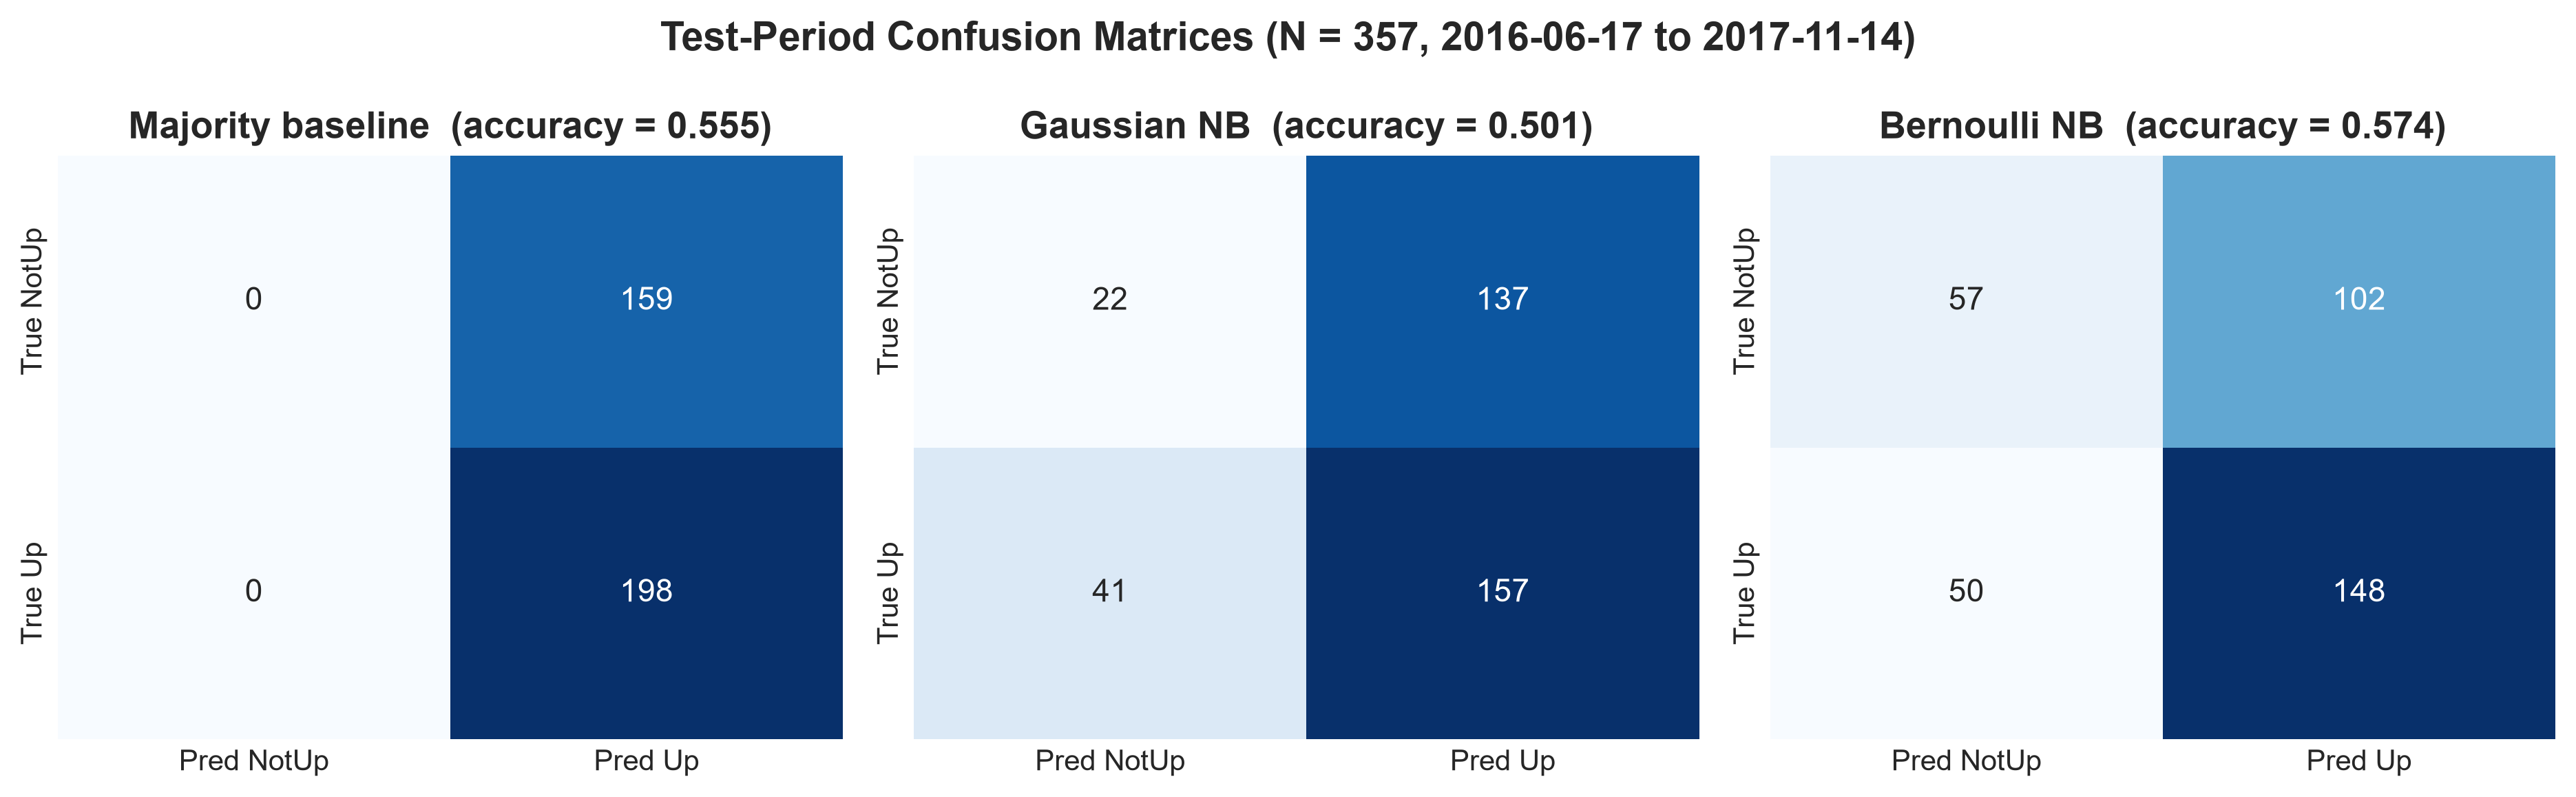

,Model,Feature,Class_0_Mean,Class_0_Var,Class_1_Mean,Class_1_Var,Class_0_Prob,Class_1_Prob,Ratio_C1_to_C0
0,GaussianNB,return_idx,0.0287,0.9558,-0.0241,1.0359,NaN,NaN,NaN
1,GaussianNB,dist_EMA50,0.0599,0.8708,-0.0504,1.1031,NaN,NaN,NaN
2,GaussianNB,volatility_20,-0.0436,0.9657,0.0367,1.0259,NaN,NaN,NaN
3,GaussianNB,term_spread,-0.0113,0.9597,0.0095,1.0337,NaN,NaN,NaN
4,GaussianNB,delta_term_spread,-0.0188,1.0069,0.0158,0.9936,NaN,NaN,NaN
5,GaussianNB,credit_spread,0.0134,0.9833,-0.0113,1.0137,NaN,NaN,NaN
6,GaussianNB,delta_credit_spread,0.0269,0.9481,-0.0226,1.0426,NaN,NaN,NaN
7,GaussianNB,Volume,-0.0066,1.1375,0.0056,0.8843,NaN,NaN,NaN


Bernoulli Feature Probabilities:


,Model,Feature,Class_0_Mean,Class_0_Var,Class_1_Mean,Class_1_Var,Class_0_Prob,Class_1_Prob,Ratio_C1_to_C0
14,BernoulliNB,Below_EMA50,NaN,NaN,NaN,NaN,0.2435,0.2809,1.1537
12,BernoulliNB,Mom5_Neg,NaN,NaN,NaN,NaN,0.3890,0.4291,1.1032
16,BernoulliNB,TermSpread_Flat,NaN,NaN,NaN,NaN,0.3155,0.3415,1.0825
15,BernoulliNB,TermSpread_Steep,NaN,NaN,NaN,NaN,0.3247,0.3479,1.0717
19,BernoulliNB,CreditSpread_Low,NaN,NaN,NaN,NaN,0.3231,0.3402,1.0529
9,BernoulliNB,SameDay_Down,NaN,NaN,NaN,NaN,0.4472,0.4652,1.0403
23,BernoulliNB,Gold_Up,NaN,NaN,NaN,NaN,0.4671,0.4858,1.0401
25,BernoulliNB,Oil_Up,NaN,NaN,NaN,NaN,0.4931,0.5039,1.0218


In [3]:
df_lik = pd.read_csv(TABLES_DIR / 'table_15_feature_likelihoods_S&P.csv')
print('Gaussian Feature Parameters:')
display(Image(filename=str(FIGURES_DIR / 'fig_13_naive_bayes_confusion_matrices.png')))
display(df_lik[df_lik['Model'] == 'GaussianNB'].head(8))
print('Bernoulli Feature Probabilities:')
display(df_lik[df_lik['Model'] == 'BernoulliNB'].sort_values(by='Ratio_C1_to_C0', ascending=False).head(8))